# Evaluation of rotational phantom data acquired using a sequence output by cmrseq

### Setup instructions

Install the necessary packages by running

`pip install numpy matplotlib pymapvbvd scipy ipykernel`

### Necessary imports including mapvbvd to read in SIEMENS raw data

In [27]:
import os
import string
import re

from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patheffects as PathEffects
import mapvbvd

from scipy import ndimage

from pint import Quantity

import cv2

### Geometrical data

In [28]:
# phantom radius
# r_phan = Quantity(6.47, 'cm')
r_phan = Quantity(6.3, 'cm')

### Load raw data

We load the file unsorted, which means we get dimensions [x, coils, others], where others include phase encodings, averages etc. By reshaping according to loop structure, the raw data has the correct dimensions.
Here, we assume a square image dimension and 4 flow encodings.

In [29]:
# Define the path and dataset number
# data_file_path = r'meas_MID00056_FID16519_cmrseq_venc50_bernstein_BW446_dyn16_rpm50_dir1.npy'

# data_file_path = r'meas_MID00086_FID16549_cmrseq_venc50_bernstein_BW446_dyn16_rpm200_dir1.npy'

# data_file_path = r'meas_MID00153_FID16616_cmrseq_venc300_bernstein_BW446_dyn16_rpm200_dir2.npy'

# data_file_path = r'meas_MID00122_FID06068_38_cor_venc300_400rpm_135cms_10avgs_dir2.npy'

# experiment
# data_file_path = r'meas_MID00226_FID16689_cmrseq_venc500_echo_BW892_dyn16_rpm500_dir2.npy'
# data = np.load(data_file_path)
# data_exp = data

# simulation
# data_file_path = 'cmrseq_venc500_echo_BW892_-500Hz_time_signal.npy'
# data = np.load(data_file_path).T
# data = np.fft.fftshift(np.fft.ifftn(np.fft.ifftshift(data, axes=(0, 1)), axes=(0, 1)), axes=(0, 1))
# data_sim = data


# experiment
data_file_path = r'meas_MID00196_FID16659_cmrseq_venc500_echo_BW892_dyn16_rpm500_dir1.npy'
data = np.load(data_file_path)
data_exp = data

# simulation
data_file_path = 'cmrseq_venc500_echo_BW892_500Hz_time_signal.npy'
data = np.load(data_file_path).T
data = np.fft.fftshift(np.fft.ifftn(np.fft.ifftshift(data, axes=(0, 1)), axes=(0, 1)), axes=(0, 1))
data_sim = data




filename = Path(data_file_path).stem
filetype = '.svg'

venc = re.search(r'venc(\d+)', data_file_path)
if venc is None:
    venc = 100
else:
    venc = float(venc.group(1))
    
rpm = re.search(r'rpm(\d+)', data_file_path)
if rpm is None:
    rpm = 0
else:
    rpm = float(rpm.group(1))
    
dir = re.search(r'dir(\d+)', data_file_path)
if dir is None:
    dir = 0
else:
    dir = float(dir.group(1))

In [30]:
print(f'Loaded data with dimensions {data.shape} and venc {venc}, rpm {rpm}, dir {dir}.')

Loaded data with dimensions (224, 224, 4) and venc 500.0, rpm 0, dir 0.


In [31]:
venc_lims = (-venc, venc)
venc_ticks = np.arange(-venc, venc*1.1, venc/2)

venc_abs_lims = (0, venc)
venc_abs_ticks = np.arange(0, venc*1.1, venc/2)

diff_fac = 0.05
venc_diff_lims = (-diff_fac*venc, diff_fac*venc)
venc_diff_ticks = np.arange(-diff_fac*venc, diff_fac*venc*1.1, diff_fac*venc/2)

# venc_abs_diff_lims = (0, diff_fac*venc)
# venc_abs_diff_ticks = np.arange(-diff_fac*venc, diff_fac*venc*1.1, diff_fac*venc/2)

ec_fac = 0.4
venc_ec_lims = (-ec_fac*venc, ec_fac*venc)
# venc_ec_ticks = np.arange(-0.1*venc, venc*0.51, venc/20)
venc_ec_ticks = np.arange(-ec_fac*venc, ec_fac*venc*1.1, ec_fac*venc/2)

### Velocity plots

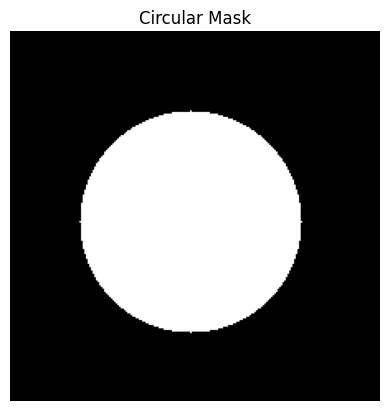

In [32]:
# mag = np.abs(np.mean(data, axis=2))
# data = np.repeat(data, repeats=4, axis=2)

mag = np.abs(data[:, :, 0])

# mask = mag > np.quantile(mag, 0.6)

# labeled_array, num_features = ndimage.label(mask)
# if num_features == 0:
#     blob_mask = np.zeros_like(mask, dtype=bool)

# sizes = ndimage.sum(mask, labeled_array, range(1, num_features + 1))
# largest_label = np.argmax(sizes) + 1  # label numbers start from 1
# blob_mask = labeled_array == largest_label

# Optional: Blur to reduce noise
norm_img = cv2.normalize(mag, None, 0, 255, cv2.NORM_MINMAX)
gray = norm_img.astype(np.uint8)

blurred = cv2.GaussianBlur(gray, (9, 9), 2)

# Detect circles using Hough Circle Transform
circles = cv2.HoughCircles(blurred, cv2.HOUGH_GRADIENT, dp=1.2, minDist=100,
                           param1=50, param2=30, minRadius=0, maxRadius=0)

# Create an empty mask
mask = np.zeros_like(gray).astype(np.uint8)

if circles is not None:
    circles = np.round(circles[0, :]).astype("int")
    # Assuming we want the first detected circle
    x, y, r = circles[0]
    # Draw the mask
    cv2.circle(mask, (x, y), r, 255, thickness=-1)  # Filled circle

    # Optional: show or save the mask
    plt.imshow(mask, cmap='gray')
    plt.title('Circular Mask')
    plt.axis('off')
    plt.show()

mask = mask / 255.

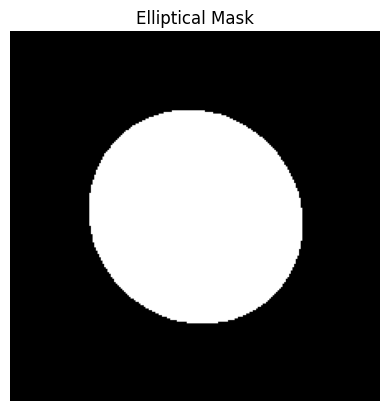

In [33]:
# Your input
mag = np.abs(data[:, :, 0])

# Normalize magnitude for better contrast
norm_img = cv2.normalize(mag, None, 0, 255, cv2.NORM_MINMAX)
gray = norm_img.astype(np.uint8)

# Thresholding: You can adjust threshold value depending on your data
_, threshed = cv2.threshold(gray, 70, 255, cv2.THRESH_BINARY)

# Optional: Blur to reduce noise
# threshed = cv2.GaussianBlur(threshed, (1, 1), 2)

# Find contours
cnts, _ = cv2.findContours(threshed, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

# Create an empty mask
ellipse_mask = np.zeros_like(gray, dtype=np.uint8)

if cnts:
    # Optionally: choose the largest contour
    cnt = max(cnts, key=cv2.contourArea)

    if len(cnt) >= 5:  # fitEllipse requires at least 5 points
        ellipse = cv2.fitEllipse(cnt)

        # Draw the ellipse onto the mask
        cv2.ellipse(ellipse_mask, ellipse, 255, thickness=-1)

        # Show the result
        plt.imshow(ellipse_mask, cmap='gray', aspect=data.shape[1]/data.shape[0])
        plt.title('Elliptical Mask')
        plt.axis('off')
        plt.show()
    else:
        print("Not enough points to fit an ellipse.")
else:
    print("No contours found.")

ellipse_mask = ellipse_mask / np.max(ellipse_mask[:])


### Find center of mass of the image (for the zero velocity case)

In [42]:
# centre = np.int64(np.round(ndimage.center_of_mass(np.abs(np.mean(data, axis=2)))))

centre = np.int64(np.round(ndimage.center_of_mass(mask)))
print(centre)

centre = np.int64(np.round(ndimage.center_of_mass(ellipse_mask)))
print(centre)

# homogeneous coordinate matrix, no rotation, no shift
rot = np.eye(4, 4)
# shift the center by integer offset
offset = centre - tuple(ti//2 for ti in data.shape[0:2])
# offset = centre - tuple(ti/2 for ti in data.shape[0:2])

print(f'Shifting image by {offset[0]} and {offset[1]} pixels.')
# adjust matrix according to offset
rot[0:2, -1] = offset

# offset[0] = -offset[0]
# offset[1] = -offset[1] - 1
# offset[1] = -1

# experiment
# offset[0] = offset[1] + 1
# offset[1] = offset[0] - 2

print(offset)
# for plotting hlines and vlines later
center_new = tuple(ti//2 for ti in data.shape[0:2]) - offset
# center_new = tuple(ti/2 for ti in data.shape[0:2]) - offset

# offset = (offset[1], offset[0])
# center_new = tuple(ti/2 for ti in data.shape[0:2]) - offset
# center_new = centre
print(center_new)

# apply translation to image
rotimg = ndimage.affine_transform(input=data, matrix=rot, order=0, output=np.complex64, mode='constant', cval=np.nan)
# rotimg = np.roll(data, axis=(0, 1), shift=offset[::-1])
data = rotimg

rotellipse_mask = ndimage.affine_transform(input=ellipse_mask.astype(int), matrix=rot[1:, 1:], order=0, output=bool, mode='constant', cval=np.nan)

# rotellipse_mask = np.roll(ellipse_mask, axis=(0, 1), shift=offset[::-1])
ellipse_mask = rotellipse_mask

# shift center back to zero
center_new = center_new + offset

center_img = np.int64(center_new)
# shift center such that coordinates resemble MR coordinate system
center_new = np.int64(center_new - (data.shape[0]/2, data.shape[1]/2))

# from scipy.ndimage import zoom
# scaled_image = zoom(data, 1.005, order=1)  # order=1 for bilinear interpolation

# print(data.shape)
# print(scaled_image.shape)

# data = scaled_image[:-1, :-1, :]

mag = np.abs(data[:, :, 0])
# mag = np.abs(np.mean(data, axis=2))
# mag = np.mean(np.abs(data), axis=2)


velx = -np.angle(data[:, :, 1] / data[:, :, 0])
# velx = np.unwrap(velx, axis=0)
vely = np.angle(data[:, :, 2] / data[:, :, 0])
velz = np.angle(data[:, :, 3] / data[:, :, 0])

velx = venc * velx / np.pi
vely = venc * vely / np.pi
velz = venc * velz / np.pi


mask_sim = ellipse_mask

mask_exp = ellipse_mask
mask_exp = np.roll(mask_exp, shift=(-3, 1), axis=(0, 1)).astype(float)
ellipse_mask = mask_exp

[115 109]
[109 113]
Shifting image by -3 and 1 pixels.
[-3  1]
[115 111]


/tmp/ipykernel_2635778/1856071649.py:67: RuntimeWarning: invalid value encountered in divide
  velx = -np.angle(data[:, :, 1] / data[:, :, 0])
/tmp/ipykernel_2635778/1856071649.py:69: RuntimeWarning: invalid value encountered in divide
  vely = np.angle(data[:, :, 2] / data[:, :, 0])
/tmp/ipykernel_2635778/1856071649.py:70: RuntimeWarning: invalid value encountered in divide
  velz = np.angle(data[:, :, 3] / data[:, :, 0])


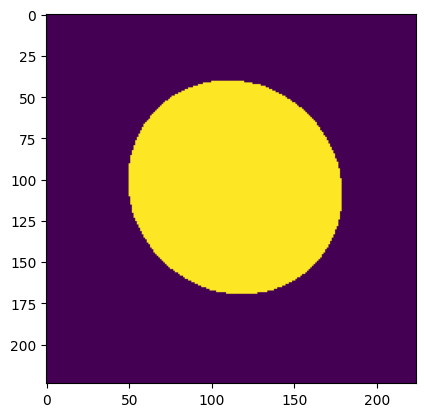

In [43]:
# mask_exp[mask_exp > 0] = True
plt.imshow(mask_exp)

In [44]:
import matplotlib
from matplotlib.colors import LinearSegmentedColormap

cmap = matplotlib.colormaps.get_cmap('twilight')  # viridis is the default colormap for imshow

# Number of colors to sample
N = 256
# Convert to a list of colors
colors = cmap(np.linspace(0, 1, N))

# Shift the colormap by 0.5 (center goes to the ends)
shifted_colors = np.roll(colors, N // 2, axis=0)

# Create a new colormap
shifted_cmap = LinearSegmentedColormap.from_list('shifted_twilight', shifted_colors)

cmap = shifted_cmap
# cmap.set_bad(color='white')
cmap.set_bad(color=cmap(0.5))

124.2148666381836 132.96165466308594
Eccentricity 0.35670857411512435
Ratio 0.9342157101830149
Plots from left to right: magnitude, magnitude venc direction 1, magnitude venc direction 2, magnitude venc direction 3


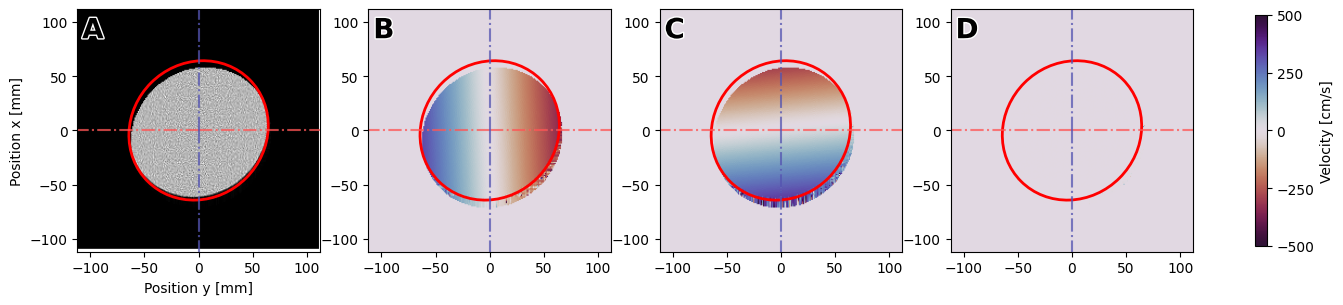

In [45]:
import matplotlib.patches as patches
import copy

(x, y), (major_axis, minor_axis), angle = ellipse
print(major_axis, minor_axis)
eccentricity = np.sqrt(1 - (major_axis / minor_axis)**2)
print(f'Eccentricity {eccentricity}')
ratio = major_axis / minor_axis
print(f'Ratio {ratio}')

# Create a matplotlib Ellipse patch
ellipse_patch = patches.Ellipse(
    (center_new[0], center_new[1]),            # Center of the ellipse
    major_axis,        # Width (major axis length)
    minor_axis,        # Height (minor axis length)
    angle=angle,       # Rotation angle in degrees
    edgecolor='r',     # Red outline
    facecolor='none',  # No fill
    linewidth=2,
    alpha=1
)

print("Plots from left to right: magnitude, magnitude venc direction 1, magnitude venc direction 2, magnitude venc direction 3")


fig0, axes = plt.subplots(nrows=1, ncols=4, figsize=(16, 4)) # figsize: pixel size for latex

im0 = axes[0].imshow(mag * ellipse_mask, cmap='gray', origin='lower', extent=(-data.shape[1]/2, data.shape[1]/2, -data.shape[0]/2, data.shape[0]/2))
# im0 = axes[0].pcolormesh(mag * mask, cmap='gray')
# axes[0].set_aspect('equal')
circle = plt.Circle(center_new, r_phan.m_as('mm'), color='r', alpha=1, fill=False, linewidth=2)
# axes[0].add_patch(circle)
axes[0].add_patch(copy.copy(ellipse_patch))
axes[0].set_aspect(data.shape[1]/data.shape[0])

im1 = axes[1].imshow(velx * ellipse_mask, cmap=cmap, origin='lower', vmin=-venc, vmax=venc, extent=(-data.shape[1]/2, data.shape[1]/2, -data.shape[0]/2, data.shape[0]/2))
circle = plt.Circle(center_new, r_phan.m_as('mm'), color='r', alpha=1, fill=False, linewidth=2)
# axes[1].add_patch(circle)
axes[1].add_patch(copy.copy(ellipse_patch))
axes[1].set_aspect(data.shape[1]/data.shape[0])

im2 = axes[2].imshow(vely * ellipse_mask, cmap=cmap, origin='lower', vmin=-venc, vmax=venc, extent=(-data.shape[1]/2, data.shape[1]/2, -data.shape[0]/2, data.shape[0]/2))
circle = plt.Circle(center_new, r_phan.m_as('mm'), color='r', alpha=1, fill=False, linewidth=2)
# axes[2].add_patch(circle)
axes[2].add_patch(copy.copy(ellipse_patch))
axes[2].set_aspect(data.shape[1]/data.shape[0])

im3 = axes[3].imshow(velz * ellipse_mask, cmap=cmap, origin='lower', vmin=-venc, vmax=venc, extent=(-data.shape[1]/2, data.shape[1]/2, -data.shape[0]/2, data.shape[0]/2))
circle = plt.Circle(center_new, r_phan.m_as('mm'), color='r', alpha=1, fill=False, linewidth=2)
# axes[3].add_patch(circle)
axes[3].add_patch(copy.copy(ellipse_patch))
axes[3].set_aspect(data.shape[1]/data.shape[0])

cbar1 = fig0.colorbar(im1, ax=(axes[:]), shrink=0.75, location='right', fraction=0.05)
cbar1.set_label('Velocity [cm/s]')
cbar1.set_ticks(np.arange(-venc, venc*1.1, venc/2)) # 21 to guarantee 20 is included.

for i, axis in enumerate(axes):
    axis.grid(False)
    x_min, x_max = axis.get_xlim()
    y_min, y_max = axis.get_ylim()
    
    axis.plot((0, x_min), (center_new[1], center_new[1]), color='white', linestyle='-.', alpha=0.5)
    axis.plot((0, x_max), (center_new[1], center_new[1]), color='white', linestyle='-.', alpha=0.5)
    axis.plot((0, x_min), (center_new[1], center_new[1]), color='red', linestyle='-.', alpha=0.5)
    axis.plot((0, x_max), (center_new[1], center_new[1]), color='red', linestyle='-.', alpha=0.5)
    
    
    axis.plot((center_new[0], center_new[0]), (0, y_min), color='white', linestyle='-.', alpha=0.5)
    axis.plot((center_new[0], center_new[0]), (0, y_max), color='white', linestyle='-.', alpha=0.5)
    axis.plot((center_new[0], center_new[0]), (0, y_max), color='darkblue', linestyle='-.', alpha=0.5)
    axis.plot((center_new[0], center_new[0]), (0, y_min), color='darkblue', linestyle='-.', alpha=0.5)
    
    # line = axis.axhline(center_new[0], color='white', linestyle='-.', alpha=0.5)
    # line.set_dashes([2, 2, 10, 2]) # 2pt line, 2pt break, 10pt line, 2pt break.
    # line = axis.axvline(center_new[1], color='white', linestyle='-.', alpha=0.5)
    # line.set_dashes([2, 2, 10, 2]) # 2pt line, 2pt break, 10pt line, 2pt break.
    
    # line = axis.axhline(center_new[0], color='black', linestyle='-.', alpha=0.5)
    # line.set_dashes([2, 2, 10, 2]) # 2pt line, 2pt break, 10pt line, 2pt break.
    # line = axis.axvline(center_new[1], color='black', linestyle='-.', alpha=0.5)
    # line.set_dashes([2, 2, 10, 2]) # 2pt line, 2pt break, 10pt line, 2pt break.
    
    # annotation inside axis
    txt = axis.text(0.02, 0.88, string.ascii_uppercase[i], transform=axis.transAxes, size=20, weight='bold')
    txt.set_path_effects([PathEffects.withStroke(linewidth=2, foreground='w')])
    
axes[0].set_ylabel('Position x [mm]')
axes[0].set_xlabel('Position y [mm]')

plt.savefig("mag_exp_dir1.svg")

plt.show()

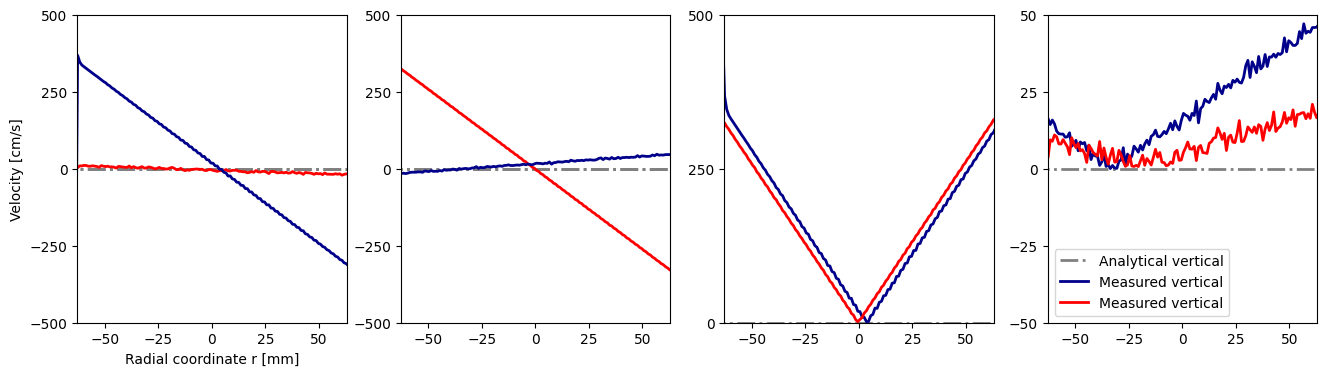

In [46]:
r_vec = np.linspace(-data.shape[0]/2, data.shape[0]/2, velx.shape[0]) # mm

v_analytic = 2*np.pi*rpm/60*r_vec / 10 # cm/s
if dir == 2:
    v_analytic = -v_analytic

fig0, axes = plt.subplots(nrows=1, ncols=4, figsize=(16, 4), sharex=True) # figsize: pixel size for latex

for axis in axes:
    axis.set_ylim((-venc, venc))
    axis.grid(False)

axes[0].plot(r_vec, -v_analytic, color='gray', linestyle='-.', linewidth=2, label='Analytical vertical')
axes[0].plot(r_vec, np.zeros_like(r_vec), color='gray', linestyle='-.', linewidth=2, label='Analytical vertical')

axes[0].plot(r_vec, velx[:, center_img[0]], color='red', linewidth=2, label='Measured vertical')
axes[0].plot(r_vec, vely[:, center_img[0]], color='darkblue', linewidth=2, label='Measured vertical')
axes[0].set_yticks(np.arange(-venc, venc*1.1, venc/2))


axes[1].plot(r_vec, v_analytic, color='gray', linestyle='-.', linewidth=2, label='Analytical vertical')
axes[1].plot(r_vec, np.zeros_like(r_vec), color='gray', linestyle='-.', linewidth=2, label='Analytical vertical')
axes[1].plot(r_vec, velx[center_img[1], :], color='red', linewidth=2, label='Measured vertical')
axes[1].plot(r_vec, vely[center_img[1], :], color='darkblue', linewidth=2, label='Measured vertical')
axes[1].set_yticks(np.arange(-venc, venc*1.1, venc/2))

axes[2].plot(r_vec, np.abs(v_analytic), color='gray', linestyle='-.', linewidth=2, label='Analytical vertical')
axes[2].plot(r_vec, np.abs(vely[:, center_img[0]]), color='darkblue', linewidth=2, label='Measured vertical')
axes[2].plot(r_vec, np.abs(velx[center_img[1], :]), color='red', linewidth=2, label='Measured vertical')
axes[2].set_ylim((0, venc))
axes[2].set_yticks(np.arange(0, venc*1.1, venc/2))

axes[3].plot(r_vec, np.zeros_like(r_vec), color='gray', linestyle='-.', linewidth=2, label='Analytical vertical')
axes[3].plot(r_vec, np.abs(vely[center_img[1], :]), color='darkblue', linewidth=2, label='Measured vertical')
axes[3].plot(r_vec, np.abs(velx[:, center_img[0]]), color='red', linewidth=2, label='Measured vertical')
axes[3].set_yticks(np.arange(-0.1*venc, venc*0.11, venc/20))
axes[3].set_ylim((-0.1*venc, 0.1*venc))

axes[0].set_ylabel('Velocity [cm/s]')
axes[0].set_xlabel('Radial coordinate r [mm]')
axes[0].set_xlim((-r_phan.m_as('mm'), r_phan.m_as('mm')))
axes[3].legend()

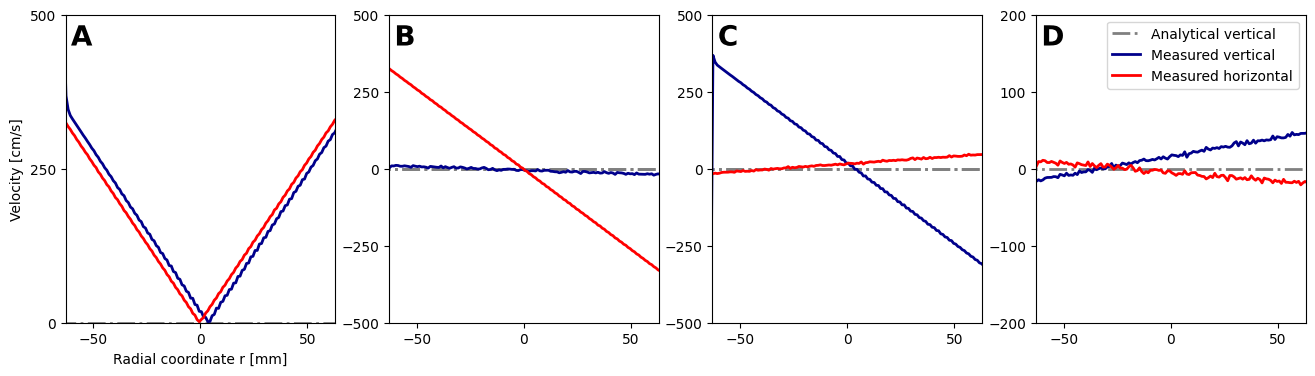

In [47]:
r_vec = np.linspace(-data.shape[0]/2, data.shape[0]/2, velx.shape[0]) # mm
r_vec2 = np.linspace(-data.shape[1]/2, data.shape[1]/2, velx.shape[1]) # mm

v_analytic = 2*np.pi*rpm/60*r_vec / 10 # cm/s
v_analytic2 = 2*np.pi*rpm/60*r_vec2 / 10 # cm/s
if dir == 2:
    v_analytic = -v_analytic
    v_analytic2 = v_analytic2

fig0, axes = plt.subplots(nrows=1, ncols=4, figsize=(16, 4), sharex=True) # figsize: pixel size for latex

for i, axis in enumerate(axes):
    axis.set_ylim(venc_lims)
    axis.grid(False)
    
    axis.set_xticks((-50, 0, 50))
    # annotation inside axis
    
    txt = axis.text(0.02, 0.9, string.ascii_uppercase[i], transform=axis.transAxes, size=20, weight='bold')
    txt.set_path_effects([PathEffects.withStroke(linewidth=2, foreground='w')])

axes[0].plot(r_vec, np.abs(v_analytic), color='gray', linestyle='-.', linewidth=2, label='Analytical vertical')
axes[0].plot(r_vec, np.abs(vely[:, center_img[0]]), color='darkblue', linewidth=2, label='Measured vertical')
axes[0].plot(r_vec2, np.abs(velx[center_img[1], :]), color='red', linewidth=2, label='Measured horizontal')
axes[0].set_ylim(venc_abs_lims)
axes[0].set_yticks(venc_abs_ticks)

axes[1].plot(r_vec, -v_analytic, color='gray', linestyle='-.', linewidth=2, label='Analytical vertical')
axes[1].plot(r_vec, np.zeros_like(r_vec), color='gray', linestyle='-.', linewidth=2, label='Analytical vertical')
axes[1].plot(r_vec, velx[:, center_img[0]], color='darkblue', linewidth=2, label='Measured vertical')
axes[1].plot(r_vec2, velx[center_img[1], :], color='red', linewidth=2, label='Measured horizontal')
axes[1].set_yticks(venc_ticks)

axes[2].plot(r_vec, -v_analytic, color='gray', linestyle='-.', linewidth=2, label='Analytical vertical')
axes[2].plot(r_vec2, np.zeros_like(r_vec2), color='gray', linestyle='-.', linewidth=2, label='Analytical vertical')
axes[2].plot(r_vec, vely[:, center_img[0]], color='darkblue', linewidth=2, label='Measured vertical')
axes[2].plot(r_vec2, vely[center_img[1], :], color='red', linewidth=2, label='Measured horizontal')
axes[2].set_yticks(venc_ticks)

axes[3].plot(r_vec, np.zeros_like(r_vec), color='gray', linestyle='-.', linewidth=2, label='Analytical vertical')
axes[3].plot(r_vec2, vely[center_img[1], :], color='darkblue', linewidth=2, label='Measured vertical')
axes[3].plot(r_vec, velx[:, center_img[0]], color='red', linewidth=2, label='Measured horizontal')
axes[3].set_yticks(venc_ec_ticks)
axes[3].set_ylim(venc_ec_lims)

axes[0].set_ylabel('Velocity [cm/s]')
axes[0].set_xlabel('Radial coordinate r [mm]')
axes[0].set_xlim((-r_phan.m_as('mm'), r_phan.m_as('mm')))
axes[3].legend()

plt.savefig(filename + '_vel' + filetype)

## Plot difference

In [48]:
data = data_exp
mag_exp = np.abs(data[:, :, 0])

velx = np.angle(data[:, :, 1] / data[:, :, 0])
vely = np.angle(data[:, :, 2] / data[:, :, 0])
velz = np.angle(data[:, :, 3] / data[:, :, 0])

velx_exp = venc * velx / np.pi
vely_exp = venc * vely / np.pi
velz_exp = venc * velz / np.pi

data = data_sim
mag_sim = np.abs(data[:, :, 0])

velx = np.angle(data[:, :, 1] / data[:, :, 0])
vely = np.angle(data[:, :, 2] / data[:, :, 0])
velz = np.angle(data[:, :, 3] / data[:, :, 0])

velx_sim = venc * velx / np.pi
vely_sim = venc * vely / np.pi
velz_sim = venc * velz / np.pi

124.2148666381836 132.96165466308594
Eccentricity 0.35670857411512435
Ratio 0.9342157101830149
Plots from left to right: magnitude, magnitude venc direction 1, magnitude venc direction 2, magnitude venc direction 3


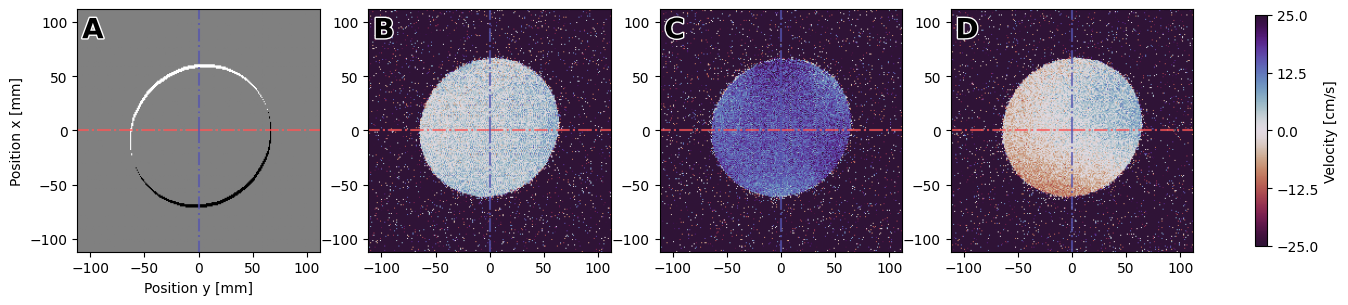

In [49]:
import matplotlib.patches as patches
import copy

# mask_exp = np.roll(mask_exp, axis=(0, 1), shift=-offset[::-1])
# mask_diff = mask_sim - np.roll(mask_exp, shift=(-1, 1), axis=(0, 1))
# mask_diff = mask_sim.astype(float) - mask_exp.astype(float)
mask_diff = mask_sim.astype(float) - mask_exp.astype(float)

(x, y), (major_axis, minor_axis), angle = ellipse
print(major_axis, minor_axis)
eccentricity = np.sqrt(1 - (major_axis / minor_axis)**2)
print(f'Eccentricity {eccentricity}')
ratio = major_axis / minor_axis
print(f'Ratio {ratio}')

# Create a matplotlib Ellipse patch
ellipse_patch = patches.Ellipse(
    (center_new[0], center_new[1]),            # Center of the ellipse
    major_axis,        # Width (major axis length)
    minor_axis,        # Height (minor axis length)
    angle=angle,       # Rotation angle in degrees
    edgecolor='r',     # Red outline
    facecolor='none',  # No fill
    linewidth=2,
    alpha=1
)

print("Plots from left to right: magnitude, magnitude venc direction 1, magnitude venc direction 2, magnitude venc direction 3")


fig0, axes = plt.subplots(nrows=1, ncols=4, figsize=(16, 4)) # figsize: pixel size for latex

im0 = axes[0].imshow(mask_diff, cmap='gray', origin='lower', extent=(-data.shape[1]/2, data.shape[1]/2, -data.shape[0]/2, data.shape[0]/2))
# im0 = axes[0].pcolormesh(mag * mask, cmap='gray')
# axes[0].set_aspect('equal')
# circle = plt.Circle(center_new, r_phan.m_as('mm'), color='r', alpha=1, fill=False, linewidth=2)
# axes[0].add_patch(circle)
# axes[0].add_patch(copy.copy(ellipse_patch))
# axes[0].set_aspect(data.shape[1]/data.shape[0])

im1 = axes[1].imshow((velx_exp - velx_sim), cmap=cmap, origin='lower', vmin=venc_diff_lims[0], vmax=venc_diff_lims[1], extent=(-data.shape[1]/2, data.shape[1]/2, -data.shape[0]/2, data.shape[0]/2))
# circle = plt.Circle(center_new, r_phan.m_as('mm'), color='r', alpha=1, fill=False, linewidth=2)
# axes[1].add_patch(circle)
# axes[1].add_patch(copy.copy(ellipse_patch))
axes[1].set_aspect(data.shape[1]/data.shape[0])

im2 = axes[2].imshow((vely_exp - vely_sim), cmap=cmap, origin='lower', vmin=venc_diff_lims[0], vmax=venc_diff_lims[1], extent=(-data.shape[1]/2, data.shape[1]/2, -data.shape[0]/2, data.shape[0]/2))
# circle = plt.Circle(center_new, r_phan.m_as('mm'), color='r', alpha=1, fill=False, linewidth=2)
# axes[2].add_patch(circle)
# axes[2].add_patch(copy.copy(ellipse_patch))
axes[2].set_aspect(data.shape[1]/data.shape[0])

im3 = axes[3].imshow((velz_exp - velz_sim), cmap=cmap, origin='lower', vmin=venc_diff_lims[0], vmax=venc_diff_lims[1], extent=(-data.shape[1]/2, data.shape[1]/2, -data.shape[0]/2, data.shape[0]/2))
# circle = plt.Circle(center_new, r_phan.m_as('mm'), color='r', alpha=1, fill=False, linewidth=2)
# axes[3].add_patch(circle)
# axes[3].add_patch(copy.copy(ellipse_patch))
axes[3].set_aspect(data.shape[1]/data.shape[0])

cbar1 = fig0.colorbar(im1, ax=(axes[:]), shrink=0.75, location='right', fraction=0.05)
cbar1.set_label('Velocity [cm/s]')
cbar1.set_ticks(np.arange(-diff_fac*venc, diff_fac*venc*1.1, diff_fac*venc/2)) # 21 to guarantee 20 is included.

for i, axis in enumerate(axes):
    axis.grid(False)
    x_min, x_max = axis.get_xlim()
    y_min, y_max = axis.get_ylim()
    
    axis.plot((0, x_min), (center_new[1], center_new[1]), color='white', linestyle='-.', alpha=0.5)
    axis.plot((0, x_max), (center_new[1], center_new[1]), color='white', linestyle='-.', alpha=0.5)
    axis.plot((0, x_min), (center_new[1], center_new[1]), color='red', linestyle='-.', alpha=0.5)
    axis.plot((0, x_max), (center_new[1], center_new[1]), color='red', linestyle='-.', alpha=0.5)
    
    
    axis.plot((center_new[0], center_new[0]), (0, y_min), color='white', linestyle='-.', alpha=0.5)
    axis.plot((center_new[0], center_new[0]), (0, y_max), color='white', linestyle='-.', alpha=0.5)
    axis.plot((center_new[0], center_new[0]), (0, y_max), color='darkblue', linestyle='-.', alpha=0.5)
    axis.plot((center_new[0], center_new[0]), (0, y_min), color='darkblue', linestyle='-.', alpha=0.5)
    
    # line = axis.axhline(center_new[0], color='white', linestyle='-.', alpha=0.5)
    # line.set_dashes([2, 2, 10, 2]) # 2pt line, 2pt break, 10pt line, 2pt break.
    # line = axis.axvline(center_new[1], color='white', linestyle='-.', alpha=0.5)
    # line.set_dashes([2, 2, 10, 2]) # 2pt line, 2pt break, 10pt line, 2pt break.
    
    # line = axis.axhline(center_new[0], color='black', linestyle='-.', alpha=0.5)
    # line.set_dashes([2, 2, 10, 2]) # 2pt line, 2pt break, 10pt line, 2pt break.
    # line = axis.axvline(center_new[1], color='black', linestyle='-.', alpha=0.5)
    # line.set_dashes([2, 2, 10, 2]) # 2pt line, 2pt break, 10pt line, 2pt break.
    
    # annotation inside axis
    txt = axis.text(0.02, 0.88, string.ascii_uppercase[i], transform=axis.transAxes, size=20, weight='bold')
    txt.set_path_effects([PathEffects.withStroke(linewidth=2, foreground='w')])
    
axes[0].set_ylabel('Position x [mm]')
axes[0].set_xlabel('Position y [mm]')

plt.savefig("simexp_diff_corr_dir1.svg")

plt.show()

NameError: name 'velx_sim' is not defined

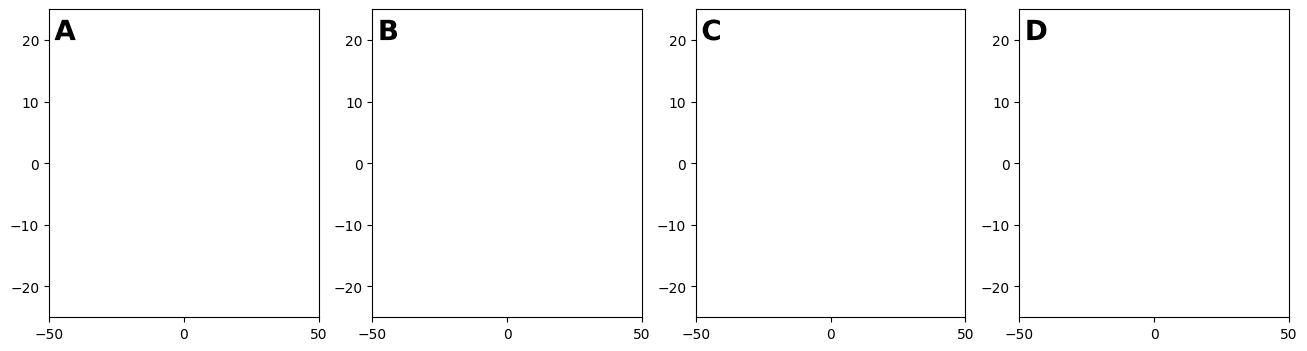

In [ ]:
r_vec = np.linspace(-data.shape[0]/2, data.shape[0]/2, velx.shape[0]) # mm
r_vec2 = np.linspace(-data.shape[1]/2, data.shape[1]/2, velx.shape[1]) # mm

v_analytic = 2*np.pi*rpm/60*r_vec / 10 # cm/s
v_analytic2 = 2*np.pi*rpm/60*r_vec2 / 10 # cm/s
if dir == 2:
    v_analytic = -v_analytic
    v_analytic2 = v_analytic2

fig0, axes = plt.subplots(nrows=1, ncols=4, figsize=(16, 4), sharex=True) # figsize: pixel size for latex

for i, axis in enumerate(axes):
    axis.set_ylim(venc_diff_lims)
    axis.grid(False)
    
    axis.set_xticks((-50, 0, 50))
    # annotation inside axis
    
    txt = axis.text(0.02, 0.9, string.ascii_uppercase[i], transform=axis.transAxes, size=20, weight='bold')
    txt.set_path_effects([PathEffects.withStroke(linewidth=2, foreground='w')])


axes[0].plot(r_vec, np.abs((velx_exp - velx_sim)[:, center_img[0]]), color='darkblue', linewidth=2, label='Difference vertical')
axes[0].plot(r_vec2, np.abs((vely_sim - vely_exp)[center_img[1], :]), color='red', linewidth=2, label='Difference horizontal')
axes[0].set_ylim(venc_diff_lims)
axes[0].set_yticks(venc_diff_ticks)

axes[1].plot(r_vec, (velx_exp - velx_sim)[:, center_img[0]], color='darkblue', linewidth=2, label='Measured vertical')
axes[1].plot(r_vec2, (velx_exp - velx_sim)[center_img[1], :], color='red', linewidth=2, label='Measured horizontal')
axes[1].set_yticks(venc_diff_ticks)

axes[2].plot(r_vec, (vely_exp - vely_sim)[:, center_img[0]], color='darkblue', linewidth=2, label='Measured vertical')
axes[2].plot(r_vec2, (vely_exp - vely_sim)[center_img[1], :], color='red', linewidth=2, label='Measured horizontal')
axes[2].set_yticks(venc_diff_ticks)

axes[3].plot(r_vec, (velz_exp - velz_sim)[:, center_img[0]], color='darkblue', linewidth=2, label='Measured vertical')
axes[3].plot(r_vec2, (velz_exp - velz_sim)[center_img[1], :], color='red', linewidth=2, label='Measured horizontal')
axes[3].set_yticks(venc_diff_ticks)
axes[3].set_ylim(venc_diff_lims)

axes[0].set_ylabel('Velocity [cm/s]')
axes[0].set_xlabel('Radial coordinate r [mm]')
axes[0].set_xlim((-r_phan.m_as('mm'), r_phan.m_as('mm')))
axes[3].legend()

plt.savefig('simexp_diff_line' + filetype)